# Fase 2: Exploración, Análisis y Preprocesamiento de Datos
**Proyecto:** Clasificación de Resoluciones de Reclamos en el Servicio de Gas Natural (ENARGAS 2026)  
**Objetivo:** Cargar el conjunto de datos, verificar su integridad, analizar la agregación de `reclamo_cantidad` y preparar las transformaciones previas al modelado.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carga del dataset original sin procesar
ruta_raw = '../data/raw/reclamos_prestadoras_2026.csv'
df = pd.read_csv(ruta_raw)

print(f"Dimensiones de la matriz agregada: {df.shape[0]} filas, {df.shape[1]} columnas")
df.head()

Dimensiones de la matriz agregada: 3454 filas, 9 columnas


,reclamo_ano,reclamo_mes_nro,reclamo_mes_nombre,reclamo_prestadora,reclamo_provincia,reclamo_grupo,reclamo_via_ingreso,reclamo_resolucion,reclamo_cantidad
0,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente,3
1,2026,1,Enero,Camuzzi Gas del Sur S.A.,Río Negro,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente,5
2,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Improcedente,4
3,2026,1,Enero,Camuzzi Gas del Sur S.A.,Tierra del Fuego Antártida e Islas del Atlánti...,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Improcedente,6
4,2026,1,Enero,Camuzzi Gas del Sur S.A.,Santa Cruz,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Improcedente,4


In [2]:
# Verificación de completitud y tipos de variables
df.info()
print("\nConteo de valores nulos por columna:")
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3454 entries, 0 to 3453
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   reclamo_ano          3454 non-null   int64 
 1   reclamo_mes_nro      3454 non-null   int64 
 2   reclamo_mes_nombre   3454 non-null   object
 3   reclamo_prestadora   3454 non-null   object
 4   reclamo_provincia    3454 non-null   object
 5   reclamo_grupo        3454 non-null   object
 6   reclamo_via_ingreso  3454 non-null   object
 7   reclamo_resolucion   3454 non-null   object
 8   reclamo_cantidad     3454 non-null   int64 
dtypes: int64(3), object(6)
memory usage: 243.0+ KB

Conteo de valores nulos por columna:
reclamo_ano            0
reclamo_mes_nro        0
reclamo_mes_nombre     0
reclamo_prestadora     0
reclamo_provincia      0
reclamo_grupo          0
reclamo_via_ingreso    0
reclamo_resolucion     0
reclamo_cantidad       0
dtype: int64


In [3]:
total_filas = len(df)
total_reclamos = df['reclamo_cantidad'].sum()

print(f"Total de registros agregados: {total_filas}")
print(f"Total acumulado de reclamos individuales: {total_reclamos:,}")

# Comparación porcentual: filas vs reclamos reales
dist_filas = df['reclamo_resolucion'].value_counts(normalize=True) * 100
dist_ponderada = (df.groupby('reclamo_resolucion')['reclamo_cantidad'].sum() / total_reclamos) * 100

comparacion_df = pd.DataFrame({
    'Distribución por Filas (%)': dist_filas.round(2),
    'Distribución Real Reclamos (%)': dist_ponderada.round(2)
})
print("\n--- Balance de Clases ---")
print(comparacion_df)

Total de registros agregados: 3454
Total acumulado de reclamos individuales: 209,491

--- Balance de Clases ---
                    Distribución por Filas (%)  Distribución Real Reclamos (%)
reclamo_resolucion                                                            
Improcedente                             56.63                           70.96
Procedente                               43.37                           29.04


C:\Users\Usuario\AppData\Local\Temp\ipykernel_12792\1440974840.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_filas.index, y=dist_filas.values, ax=axes[0], palette=['#4A90E2', '#50E3C2'])
C:\Users\Usuario\AppData\Local\Temp\ipykernel_12792\1440974840.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=dist_ponderada.index, y=dist_ponderada.values, ax=axes[1], palette=['#D0021B', '#F5A623'])


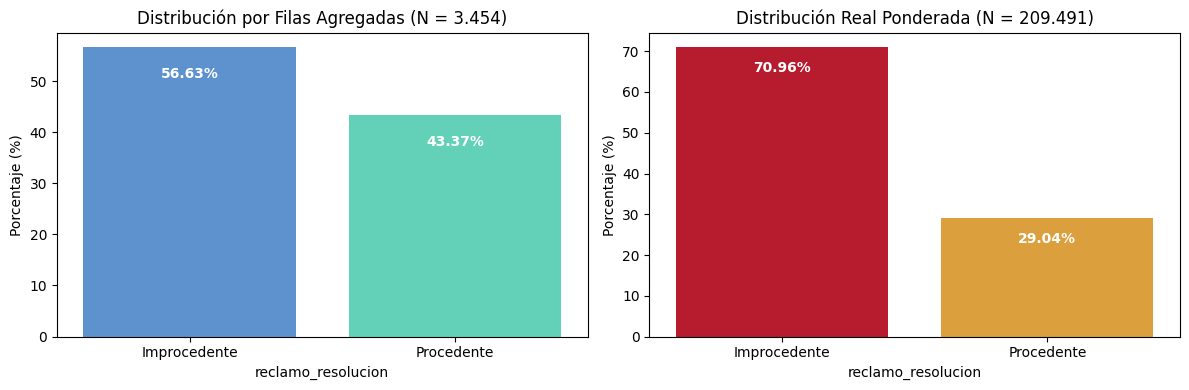

In [4]:
# Visualización del balance de clases: Filas vs Reclamos Reales
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Gráfico 1: Porcentaje de filas agregadas
sns.barplot(x=dist_filas.index, y=dist_filas.values, ax=axes[0], palette=['#4A90E2', '#50E3C2'])
axes[0].set_title('Distribución por Filas Agregadas (N = 3.454)')
axes[0].set_ylabel('Porcentaje (%)')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height() - 6),
                    ha='center', color='white', fontweight='bold')

# Gráfico 2: Porcentaje real ponderado por reclamo_cantidad
sns.barplot(x=dist_ponderada.index, y=dist_ponderada.values, ax=axes[1], palette=['#D0021B', '#F5A623'])
axes[1].set_title('Distribución Real Ponderada (N = 209.491)')
axes[1].set_ylabel('Porcentaje (%)')
for p in axes[1].patches:
    axes[1].annotate(f'{p.get_height():.2f}%', (p.get_x() + p.get_width() / 2., p.get_height() - 6),
                    ha='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### Conclusión del Análisis Exploratorio sobre la Unidad de Análisis:
* **Falsa simetría en filas agregadas:** Si se analizara el archivo fila por fila, las clases parecerían moderadamente balanceadas (56,6% vs. 43,4%).
* **Desbalance real a nivel reclamo:** Al ponderar por la cantidad efectiva de trámites presentados por usuarios, se observa que casi el **71% de los reclamos resultan Improcedentes**, frente a un **29% de Procedentes**.
* **Resolución técnica:** Para evitar *data leakage* (fuga de información) y garantizar que cada fila represente un trámite individual al momento de su ingreso, se expanden las filas replicándolas según el valor de `reclamo_cantidad`.

In [5]:
# Desagregación de instancias: expandir las filas según reclamo_cantidad
df_unitario = df.loc[df.index.repeat(df['reclamo_cantidad'])].drop(columns=['reclamo_cantidad']).reset_index(drop=True)

print(f"Dimensiones del dataset unitario: {df_unitario.shape[0]:,} filas y {df_unitario.shape[1]} columnas")
print("\nPrimeras 3 filas desagregadas (cada fila es un reclamo unitario):")
df_unitario.head(3)

Dimensiones del dataset unitario: 209,491 filas y 8 columnas

Primeras 3 filas desagregadas (cada fila es un reclamo unitario):


,reclamo_ano,reclamo_mes_nro,reclamo_mes_nombre,reclamo_prestadora,reclamo_provincia,reclamo_grupo,reclamo_via_ingreso,reclamo_resolucion
0,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente
1,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente
2,2026,1,Enero,Camuzzi Gas del Sur S.A.,Chubut,I - FACTURACION Y GESTION DE DEUDAS,CHAT,Procedente


In [6]:
# 1. Definición de predictores (X) conocidos al ingreso del reclamo
columnas_predictoras = [
    'reclamo_mes_nro',
    'reclamo_prestadora',
    'reclamo_provincia',
    'reclamo_grupo',
    'reclamo_via_ingreso'
]

X = df_unitario[columnas_predictoras].copy()

# 2. Binarización de la variable objetivo (y): Procedente = 1, Improcedente = 0
y = (df_unitario['reclamo_resolucion'] == 'Procedente').astype(int)

# 3. Codificación One-Hot de las variables categóricas (evitando multicolinealidad con drop_first)
X_encoded = pd.get_dummies(X, drop_first=True, dtype=int)

print(f"Dimensiones de la matriz de entrada (X): {X_encoded.shape}")
print(f"Distribución del target binario (y):")
print(y.value_counts(normalize=True).round(4))

Dimensiones de la matriz de entrada (X): (209491, 44)
Distribución del target binario (y):
reclamo_resolucion
0    0.7096
1    0.2904
Name: proportion, dtype: float64


In [7]:
# Consolidamos la matriz preprocesada y el target para la fase de modelado
df_procesado = X_encoded.copy()
df_procesado['target_procedente'] = y

ruta_processed = '../data/processed/reclamos_procesados_2026.csv'
df_procesado.to_csv(ruta_processed, index=False)

print(f"Archivo guardado exitosamente en: {ruta_processed}")
print(f"Total de registros exportados: {len(df_procesado):,}")

Archivo guardado exitosamente en: ../data/processed/reclamos_procesados_2026.csv
Total de registros exportados: 209,491
